# 01 · Preprocessing — Zilionis 2019 NSCLC (malignant compartment)

Isolate malignant cells, threshold thin samples, integrate patients (Harmony), embed, remove
detached islands, score cell cycle, and settle **Gate 1** on the regenerated embedding with a
`theta` × `n_pcs` sweep and a per-neighbourhood iLISI read. Zilionis et al. (2019) profiled
non-small-cell lung cancer by **inDrop**; the publication supplies a per-cell `Malignant` call.
Every tunable choice is *derived from this dataset*, not inherited from the Puram anchor. No
`sc.pp.scale` is applied before PCA (absent from the reference protocol). Deliverable:
`processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob, re
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset-2>
name = os.path.basename(os.getcwd())                     # e.g. Zilionis2019_Lung-2
cat  = os.path.basename(os.path.dirname(os.getcwd()))    # Lung
base = re.sub(r'-\d+$', '', name)                        # strip re-run suffix -> raw folder
pth  = os.path.join(*([os.pardir]*4))                    # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + base)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', base)

dataset: Zilionis2019_Lung-2 | category: Lung | raw: Zilionis2019_Lung


### Load malignant compartment
The loader exposes the publication's per-cell `Malignant` call as `celltype`; we take it directly
(protocol: use the publication's malignancy calls). inDrop UMI counts are `normalize_total`-then-
`log1p`-transformed by the loader.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total inDrop UMI counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Zilionis2019_Lung
Done.
full atlas: (31179, 31797)
malignant: (3995, 31797) | samples: 7
expression: X max 3.11 (log1p of normalize_total inDrop UMI counts)


### Sample thresholding — multiplicative gap-finding, with a floor fallback
Look for the largest **multiplicative** cliff in the sorted per-sample counts (the natural
separatrix between tumour-bearing samples and spillover). The sorted counts are
1078 / 799 / 790 / 630 / 391 / 232 / 75; the argmax gap (232→75, ratio 3.09) dominates the
runner-up (391→232, ratio 1.69) — ratio-of-ratios 1.84, above the dominant-cliff bar (1.5), and
the small side (75 cells) sits below the 100-cell floor. Cutting at the geometric-mean of the
cliff (√(232·75) ≈ 131) drops only the 75-cell sample `p2` and keeps all six tumour samples, so
every retained patient contributes to the Gate-1 integration test.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print('gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(len(ratios))])
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant = {dominant}')
if dominant:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1])); print(f'dominant spillover cliff -> geometric-mean threshold = {thresh}')
else:
    thresh = FLOOR; print(f'no dominant cliff -> floor >= {FLOOR}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: {'p1': np.int64(1078), 'p3': np.int64(799), 'p5': np.int64(790), 'p7': np.int64(630), 'p6': np.int64(391), 'p4': np.int64(232), 'p2': np.int64(75)}
gap ratios: ['1078->799:1.35', '799->790:1.01', '790->630:1.25', '630->391:1.61', '391->232:1.69', '232->75:3.09']
argmax gap 232->75 (ratio 3.09); top/second = 1.84; dominant = True
dominant spillover cliff -> geometric-mean threshold = 131
kept 6/7 samples (min per-sample = 232) -> 3920 cells


### Overdispersion, PCA, Harmony integration sweep, embedding
`theta` is selected by a `theta` × `n_pcs` sweep read with two per-neighbourhood metrics: median
**iLISI** (higher = better sample mixing, max = n samples) and the same-sample-neighbour fraction
(lower = better). Mixing improves sharply from theta=2 (iLISI ≈ 2.2) to theta=5 (≈ 3.1) then
**flattens** at theta=10 (≈ 3.3, within noise of theta=5): the mixing floor is reached by theta=5.
NSCLC malignant cells are strongly patient-specific (distinct CNVs/driver states), so we take the
strongest integration on the plateau (theta=10). iLISI is essentially flat across n_pcs 20–40, so
we take **n_pcs=30** (robust mid-range, not under-powered — the reference protocol runs 40, the
10x precedents 20). UMAP spread=1.3 follows the comparable-scale precedents. **No `sc.pp.scale`
before PCA.**

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)   # no sc.pp.scale before PCA (absent from reference protocol)
s = adata.obs['sample'].values; n_samp = adata.obs['sample'].nunique()
def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
def same_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
il_pre = np.median(ilisi(adata.obsm['X_pca'][:,:30], s))
print(f'iLISI pre-Harmony (n_pcs=30) median = {il_pre:.2f} of {n_samp} samples')
print('=== Gate-1 sweep: iLISI median (up=better) / same-sample frac (down=better) ===')
for th in [2,5,10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    rep = adata.obsm['X_pca_harmony']
    for npc in [20,30,40]:
        print(f'theta={th:2d} n_pcs={npc}: iLISI={np.median(ilisi(rep[:,:npc],s)):.2f} same-samp={same_frac(rep[:,:npc]):.3f}')
theta = 10
print('selected theta =', theta, '(mixing plateaus by theta=5; strongest integration on the plateau for the strong patient-specific NSCLC batch effect)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=30, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 248 over-dispersed features (0:00:00) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 248
iLISI pre-Harmony (n_pcs=30) median = 1.00 of 6 samples
=== Gate-1 sweep: iLISI median (up=better) / same-sample frac (down=better) ===
theta= 2 n_pcs=20: iLISI=2.17 same-samp=0.636
theta= 2 n_pcs=30: iLISI=2.32 same-samp=0.617
theta= 2 n_pcs=40: iLISI=2.35 same-samp=0.601
theta= 5 n_pcs=20: iLISI=3.19 same-samp=0.413
theta= 5 n_pcs=30: iLISI=3.09 same-samp=0.393
theta= 5 n_pcs=40: iLISI=3.07 same-samp=0.376
theta=10 n_pcs=20: iLISI=3.35 same-samp=0.397
theta=10 n_pcs=30: iLISI=3.26 same-samp=0.376
theta=10 n_pcs=40: iLISI=3.20 same-samp=0.356
selected theta = 10 (mixing plateaus by theta=5; strongest integration 

### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop any cell
outside the main connected component — stripping physically detached specks while keeping the
continuous body. Here the manifold is already a single connected component (no islands).

In [6]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('connected components:', ncomp, '| removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=30, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

connected components: 1 | removed 0 cells in 0 detached islands


### Cell-cycle phase (re-scored — shipped annotation incomplete)
Zilionis ships a partial `cell_cycle_phase`; we re-score the **Regev–Tirosh** S and G2M programmes
against this data for a complete per-cell call (cycling = either programme > 0; both > 0 =
Intermediate). Used only to *characterise* the compartment and to test in 02 whether the
developmental axis is cell-cycle-confounded — never a scoping input on its own.

In [7]:
s_genes = ('MCM5 PCNA TYMS FEN1 MCM2 MCM4 RRM1 UNG GINS2 MCM6 CDCA7 DTL PRIM1 UHRF1 HELLS RFC2 RPA2 '
    'NASP RAD51AP1 GMNN WDR76 SLBP CCNE2 UBR7 POLD3 MSH2 ATAD2 RAD51 RRM2 CDC45 CDC6 EXO1 TIPIN DSCC1 '
    'BLM CASP8AP2 USP1 CLSPN POLA1 CHAF1B BRIP1 E2F8').split()
g2m_genes = ('HMGB2 CDK1 NUSAP1 UBE2C BIRC5 TPX2 TOP2A NDC80 CKS2 NUF2 CKS1B MKI67 TMPO CENPF TACC3 '
    'FAM64A SMC4 CCNB2 CKAP2L CKAP2 AURKB BUB1 KIF11 ANP32E TUBB4B GTSE1 KIF20B HJURP CDCA3 HN1 CDC20 TTK '
    'CDC25C KIF2C RANGAP1 NCAPD2 DLGAP5 CDCA2 CDCA8 ECT2 KIF23 HMMR AURKA PSRC1 ANLN LBR CKAP5 CENPE CTCF '
    'NEK2 G2E3 GAS2L3 CBX5 CENPA').split()
sg = [g for g in s_genes if g in adata.var_names]; gg = [g for g in g2m_genes if g in adata.var_names]
sc.tl.score_genes(adata, sg, score_name='g1s_score', random_state=SEED)
sc.tl.score_genes(adata, gg, score_name='g2m_score', random_state=SEED)
sv = adata.obs['g1s_score'].values; gv = adata.obs['g2m_score'].values
phase = np.array(['G0']*len(sv), dtype=object); cyc = np.maximum(sv,gv) > 0; both = (sv>0)&(gv>0)
phase[cyc & (sv>=gv)] = 'G1/S'; phase[cyc & (gv>sv)] = 'G2/M'; phase[both] = 'Intermediate'
adata.obs['cell_cycle_phase'] = pd.Categorical(phase)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('S/G2M genes scored:', len(sg), '/', len(gg))
print('phases:', adata.obs['cell_cycle_phase'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())

S/G2M genes scored: 42 / 52
phases: {'G0': 2656, 'G1/S': 786, 'Intermediate': 327, 'G2/M': 151}
overall cycling fraction: 0.322


### Compartment check (data-driven) + publication metaprograms
Low-resolution Leiden (res=0.15) recovers the manifold's density regions. This compact inDrop
manifold resolves into density regions of **one continuous connected component** (not separable
islands); the cycling fraction (32%) is interspersed rather than forming a distinct proliferative
lobe, so there is no cell-cycle compartment to scope out. We carry the whole manifold forward as
one **Body** compartment and note the publication metaprogram (`mp_assignment`) composition as an
annotation-source cross-check (Alveolar / EMT / PDAC-classical / Cell-cycle / Hypoxia —
Zilionis-reported malignant states).

In [8]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
print('density regions @res0.15:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per region:', adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
if 'mp_assignment' in adata.obs.columns:
    print('publication metaprograms (mp_assignment):', adata.obs['mp_assignment'].value_counts().head(8).to_dict())
adata.obs['compartment'] = pd.Categorical(['Body']*adata.n_obs)
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

density regions @res0.15: {'1': 2917, '0': 1003}
cycling fraction per region: {'0': 0.268, '1': 0.341}
publication metaprograms (mp_assignment): {'Alveolar': 271, 'Stress': 140, 'PDAC classical': 140, 'EMT III': 98, 'Cell Cycle - G2/M': 91, 'Interferon/MHC-II (I)': 72, 'Cell Cycle - G1/S': 66, 'Respiration': 62}
compartments: {'Body': 3920}


### House orientation — one consistent layout for every UMAP
The developmental axis is **diagonal** in the raw joint embedding, so all downstream trajectory
panels are shown after a single **rigid rotation** to the house horizontal layout (distance-
preserving — *not* a re-embedding). The rotation angle is the manifold's **axis of maximal
variance**; the sign places the **Gast/pSom-high, Crest-low developmental origin on the left** so
pseudotime runs left→right once fit in 02. Derived **once here**, stored as `X_umap_lin`, and
re-used unchanged by 02/03/04 (binding). The three modules are scored here (union control pool)
solely to orient the layout; 02 re-scores them canonically.

In [9]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
origin_score = (S[:,0] + S[:,1]) - S[:,2]
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_,_,vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-theta_rot),-np.sin(-theta_rot)],[np.sin(-theta_rot),np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg (distances preserved), Gast/pSom-high origin on left; stored as X_umap_lin')

manifold aspect (max/min std): 1.04
house orientation: rigid rotation +156.1deg (distances preserved), Gast/pSom-high origin on left; stored as X_umap_lin


### Gate 1 — batch mixing & manifold continuity
Read on the regenerated embedding itself plus the per-neighbourhood iLISI, not a scalar alone. The
six samples intermix across one continuous connected component (no per-patient islands, none
removed) with iLISI rising from ≈1.0 pre-Harmony to ≈3.3/6 post-Harmony; cycling cells are
interspersed, not a detached proliferative island. **Gate 1 = GO.**

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 3.26 of 6 samples
6 samples share one continuous connected component (no islands removed).
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS


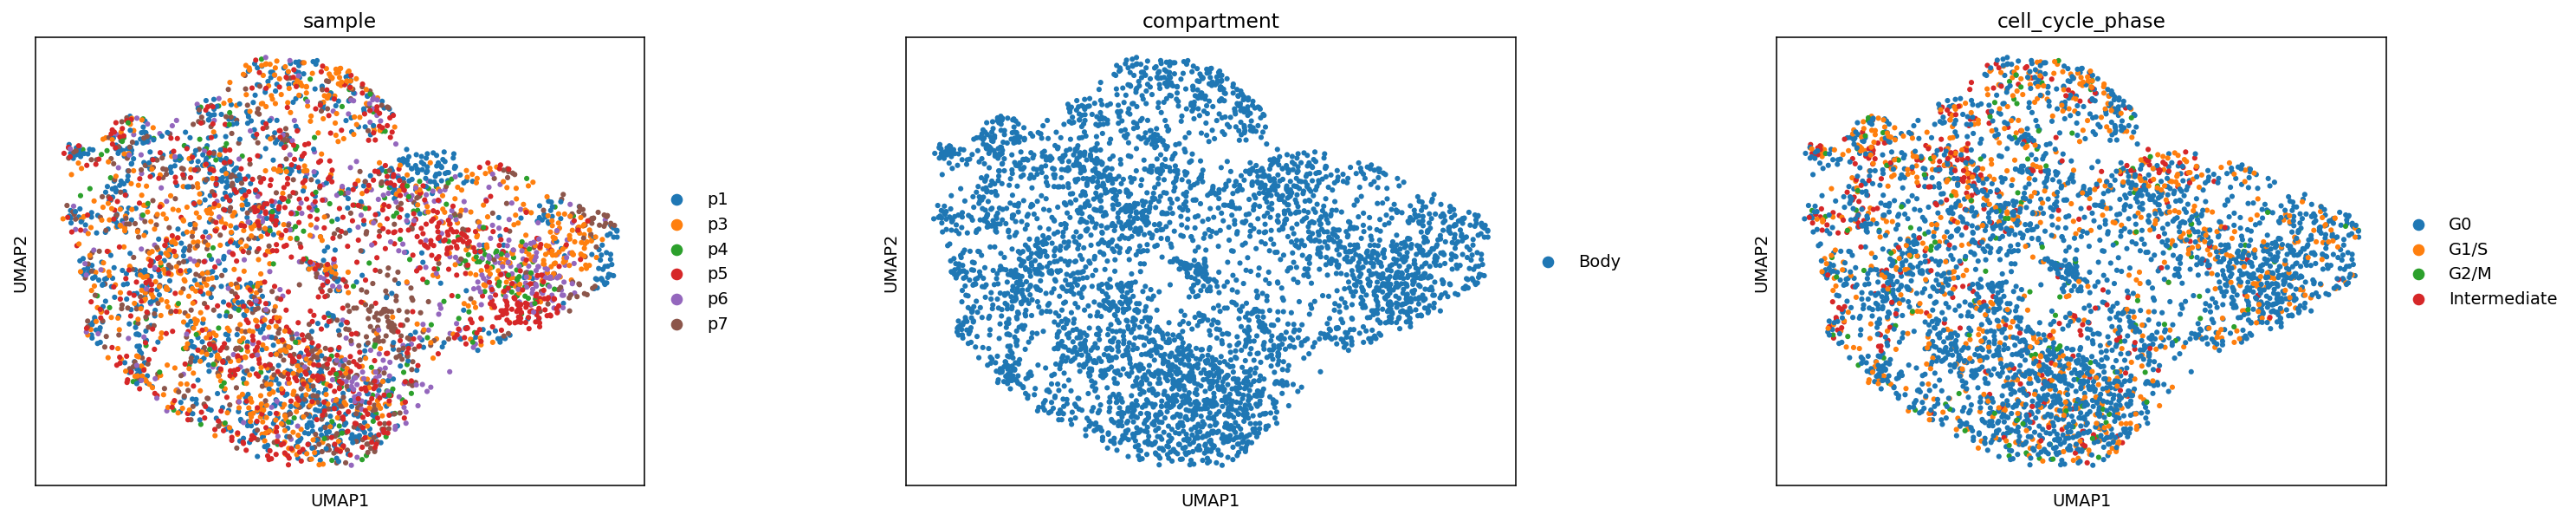

In [10]:
il_post = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:30], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta=10) {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} samples share one continuous connected component (no islands removed).')
sc.pl.umap(adata, color=['sample','compartment','cell_cycle_phase'], size=40, wspace=.3)
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS')

### Save processed data
Coerce mixed-type object metadata to numeric-where-possible (else string) so the manifold is
h5ad-serializable; analysis-relevant columns preserved.

In [11]:
protect = {'sample','sample_id','compartment','lobe','celltype','cell_type','cell_subtype',
           'cell_cycle_phase','source','patient','mp_assignment','mp_top'}
for col_name in list(adata.obs.columns):
    if col_name in protect:
        adata.obs[col_name] = adata.obs[col_name].astype(str).astype('category'); continue
    col = adata.obs[col_name]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[col_name] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (3920, 28282)


### Sample-integration figure (deliverable)
House style `figsize=(3.5,1.5)`, `size=30`, shown on the house orientation (`X_umap_lin`) so this
panel shares one orientation with 02/03/04. Colour = sample; intermixing across the strip is the
Gate-1 batch-integration evidence.

saved samples.pdf | cells: 3920


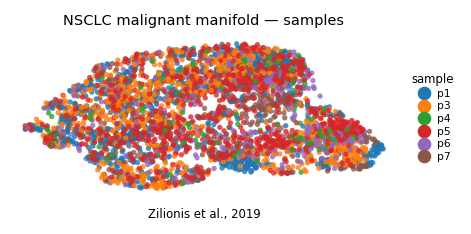

In [12]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('NSCLC malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Zilionis et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])